## San Diego VMT Study

# Import Libraries

In [470]:
import numpy as np # Core numerical and array operations
import pandas as pd # Data table and analysis operations
import matplotlib.pyplot as plt # Plotting; syntax and appearance similar to Matlab
import pathlib # file handling robust to switching between Mac, PC, and Linux platforms
import geopandas as gpd # GIS functionality added to pandas. We will use lightly here to make a map.
import seaborn as sns # use this for correlation matrix for top-level feature selection analysis

# VMT Data Import

In [471]:
cwd = pathlib.Path().cwd()
cwd


PosixPath('/Users/dvg/Documents/USF/Fall 2026/Urban Energy/git/The858')

In [472]:
inputdir = cwd / 'inputdata' # pathlib abstracts the Mac vs. PC syntax difference using '/' not as a string
inputdir

PosixPath('/Users/dvg/Documents/USF/Fall 2026/Urban Energy/git/The858/inputdata')

In [473]:
datafile = inputdir / 'CARB-UCB-CA_VMT_Estimates_DataVintage_Oct2025_PRELIMINARY_FOR_STUDENT_USE.csv'


# View Data

In [474]:
data = pd.read_csv(datafile)
data.head(10)


,1,GEOID,RetDens_bg_z,DensBusStops_one_z,NetLoadDens_GF18_two_z,JobsWi45_transit_to_car_ratio,JobsWithin45_Car_z,StreetDens_GF18_two_z,cbsa_IE,cbsa_LA_OC,VMT_state,VMT_state_trunc,VMT_diff_state,VMT_CBSA,VMT_CBSA_trunc,VMT_diff_CBSA
0,2,60259400003,0.130,0.362,3.634,-0.190,0.735,0.3702,0.0,0.0000,5.040,5.040,6.370,5.040,5.040,3.273
1,3,60250108002,0.133,0.362,3.500,0.000,0.698,0.4617,0.0,0.0000,5.155,5.155,6.486,5.155,5.155,3.388
2,4,60250108001,0.133,0.362,3.511,0.000,0.692,0.4865,0.0,0.0000,5.185,5.185,6.515,5.185,5.185,3.418
3,5,60250111003,0.133,0.362,3.513,0.000,0.681,0.4965,0.0,0.0000,5.185,5.185,6.516,5.185,5.185,3.418
4,6,60730100132,-0.025,0.042,-2.598,-0.764,-0.048,-0.2850,0.0,0.0000,-3.677,-3.677,-2.346,-3.677,-3.677,-2.384
5,7,60373104003,-0.115,-0.090,-6.003,-0.839,-2.742,-0.0708,0.0,2.4049,-7.456,-7.456,-6.125,-9.861,-9.861,-3.887
6,8,60310007014,0.124,0.362,0.172,-0.354,0.567,-0.0103,0.0,0.0000,0.860,0.860,2.191,0.860,0.860,-0.968
7,9,60310003002,0.132,0.362,0.889,0.000,0.711,-0.1259,0.0,0.0000,1.968,1.968,3.298,1.968,1.968,0.140
8,10,60310002002,0.133,0.362,3.701,0.000,0.699,0.4480,0.0,0.0000,5.343,5.343,6.674,5.343,5.343,3.515
9,11,60590865023,0.133,0.362,-3.051,-0.542,-3.067,-0.4123,0.0,2.4049,-4.172,-4.172,-2.841,-6.577,-6.577,-0.603


# Clean GEOID Column

In [475]:
data['GEOID'] = data['GEOID'].map(str).str.zfill(12)
data.head()

,1,GEOID,RetDens_bg_z,DensBusStops_one_z,NetLoadDens_GF18_two_z,JobsWi45_transit_to_car_ratio,JobsWithin45_Car_z,StreetDens_GF18_two_z,cbsa_IE,cbsa_LA_OC,VMT_state,VMT_state_trunc,VMT_diff_state,VMT_CBSA,VMT_CBSA_trunc,VMT_diff_CBSA
0,2,060259400003,0.130,0.362,3.634,-0.190,0.735,0.3702,0.0,0.0,5.040,5.040,6.370,5.040,5.040,3.273
1,3,060250108002,0.133,0.362,3.500,0.000,0.698,0.4617,0.0,0.0,5.155,5.155,6.486,5.155,5.155,3.388
2,4,060250108001,0.133,0.362,3.511,0.000,0.692,0.4865,0.0,0.0,5.185,5.185,6.515,5.185,5.185,3.418
3,5,060250111003,0.133,0.362,3.513,0.000,0.681,0.4965,0.0,0.0,5.185,5.185,6.516,5.185,5.185,3.418
4,6,060730100132,-0.025,0.042,-2.598,-0.764,-0.048,-0.2850,0.0,0.0,-3.677,-3.677,-2.346,-3.677,-3.677,-2.384


In [476]:
data_cleaned = data.set_index('GEOID')[['VMT_diff_state']]
data_cleaned.head()

,VMT_diff_state
GEOID,
060259400003,6.370
060250108002,6.486
060250108001,6.515
060250111003,6.516
060730100132,-2.346


In [477]:
data_cleaned.describe()

,VMT_diff_state
count,23190.000000
mean,-0.256459
std,4.770563
min,-14.135000
25%,-2.704750
50%,0.303000
75%,2.936000
max,10.676000


# Calculate State-wide VMT Baseline using EMFAC (LDA, LDT1, LDT2, MCY)

In [478]:
VMT_state = 716/39.5 # sum of VMT from downloaded spreadsheet divided by California population

In [479]:
vmt = data_cleaned + VMT_state # important distinction between EMFAC (VMT_state), which is VMT driven within the boundaries of the state 
# and neighborhood data which are miles driven by residents of the state (data_clearned)

vmt = vmt.rename({'VMT_diff_state': 'VMTpc'}, axis=1)
vmt.describe()

,VMTpc
count,23190.000000
mean,17.870123
std,4.770563
min,3.991582
25%,15.421832
50%,18.429582
75%,21.062582
max,28.802582


# Visualization

In [480]:
ca_cbg_shapefile_path = inputdir / 'cb_2019_06_bg_500k' / 'cb_2019_06_bg_500k.shp'
gdf = gpd.read_file(ca_cbg_shapefile_path) # Basic geopandas read; it will figure out it is a shapefile format.
gdf.head() # dataframe functions are inherited by geodataframes, in addition to geodataframe specific functions. 

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry
0,06,037,800408,1,1500000US060378004081,060378004081,1,BG,2792751,1500447,"POLYGON ((-118.78754 34.02718, -118.78607 34.0..."
1,06,041,124200,4,1500000US060411242004,060411242004,4,BG,2259455,973726,"POLYGON ((-122.48698 37.89918, -122.48416 37.9..."
2,06,059,062619,4,1500000US060590626194,060590626194,4,BG,369794,343273,"POLYGON ((-117.77753 33.53639, -117.77558 33.5..."
3,06,051,000101,1,1500000US060510001011,060510001011,1,BG,2978150540,1148631,"POLYGON ((-118.94597 37.77522, -118.94348 37.7..."
4,06,093,000200,1,1500000US060930002001,060930002001,1,BG,1300052761,72751421,"POLYGON ((-122.25174 41.75805, -122.24754 41.7..."


<Axes: >

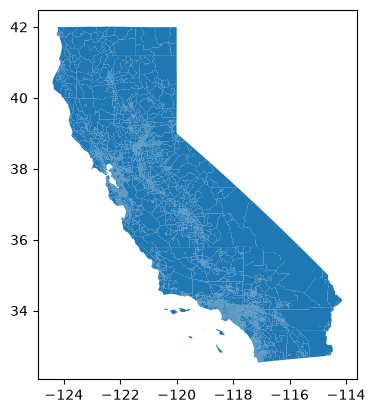

In [481]:
gdf.plot()

In [482]:
gdf['ALAND'].sum() / 1e6 # convert m^2 to km^2

np.float64(403660.088482)

# Extract San Diego Data

In [483]:
# San Diego FIPS code = 073
sd_shape = gdf[gdf['COUNTYFP'] == '073']
len(gdf)

23196

<Axes: >

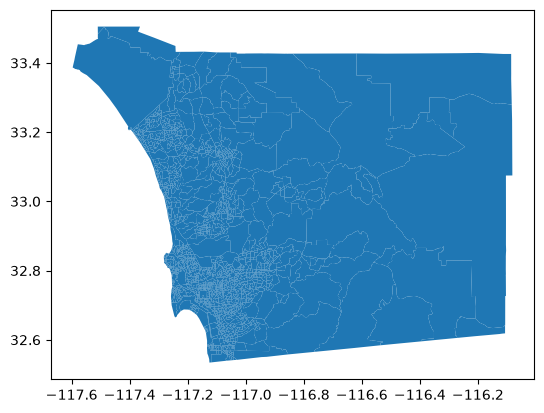

In [484]:
sd_shape.plot()

# Merge

In [485]:
merged = sd_shape.merge(vmt, left_on='GEOID', right_index=True, how='inner')
len(merged)

1794

In [486]:
merged.head()

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry,VMTpc
27,06,073,003305,1,1500000US060730033051,060730033051,1,BG,441435,0,"POLYGON ((-117.09519 32.70412, -117.09492 32.7...",15.308582
36,06,073,008347,2,1500000US060730083472,060730083472,2,BG,408199,0,"POLYGON ((-117.15141 32.92595, -117.15186 32.9...",17.900582
39,06,073,008006,3,1500000US060730080063,060730080063,3,BG,109500,0,"POLYGON ((-117.26217 32.80799, -117.25928 32.8...",17.273582
85,06,073,015801,1,1500000US060730158011,060730158011,1,BG,430195,0,"POLYGON ((-116.96235 32.79911, -116.9581 32.79...",15.260582
94,06,073,011601,2,1500000US060730116012,060730116012,2,BG,222974,0,"POLYGON ((-117.10356 32.6672, -117.09535 32.66...",14.350582


In [487]:
sd_vmt = merged.set_index('GEOID')[['VMTpc', 'geometry']]
sd_vmt.head()

,VMTpc,geometry
GEOID,,
060730033051,15.308582,"POLYGON ((-117.09519 32.70412, -117.09492 32.7..."
060730083472,17.900582,"POLYGON ((-117.15141 32.92595, -117.15186 32.9..."
060730080063,17.273582,"POLYGON ((-117.26217 32.80799, -117.25928 32.8..."
060730158011,15.260582,"POLYGON ((-116.96235 32.79911, -116.9581 32.79..."
060730116012,14.350582,"POLYGON ((-117.10356 32.6672, -117.09535 32.66..."


# VMT Map

<Axes: >

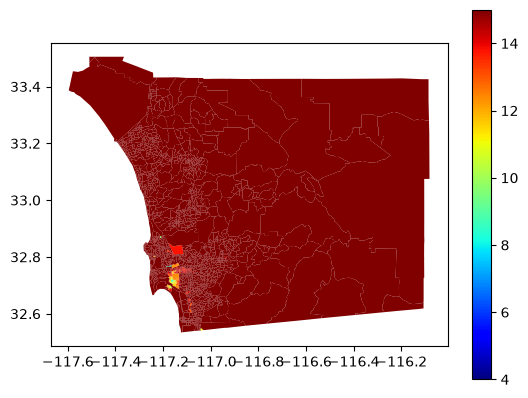

In [488]:
sd_vmt.plot(column='VMTpc', legend=True, cmap='jet', vmin=4, vmax=15)


# Merge with ACS population and housing Data

In [489]:
ca_pop_data_file = inputdir / 'ACSDT5Y2019.B01003_2026-09-27T122429' / 'ACSDT5Y2019.B01003-Data.csv'
ca_pop_data = pd.read_csv(ca_pop_data_file)
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4
0,Geography,Geographic Area Name,Estimate!!Total,Margin of Error!!Total,NaN
1,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN
2,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN
3,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN
4,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN


In [490]:
ca_pop_data = pd.read_csv(ca_pop_data_file, skiprows=[1])
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4
0,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN
1,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN
2,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN
3,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN
4,1500000US060014003002,"Block Group 2, Census Tract 4003, Alameda Coun...",1237,263,NaN


Trim Geoid 15000000US Prefix

In [491]:
ca_pop_data['GEOID'] = ca_pop_data['GEO_ID'].map(lambda x: x[9:]) # remove first nine characters
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4,GEOID
0,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN,060014001001
1,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN,060014002001
2,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN,060014002002
3,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN,060014003001
4,1500000US060014003002,"Block Group 2, Census Tract 4003, Alameda Coun...",1237,263,NaN,060014003002


Set GEOID as Index, rename column of interest, and drop remainder

In [492]:
pop = ca_pop_data.set_index('GEOID')[['B01003_001E']].rename({'B01003_001E': 'Population'}, axis=1)
pop.head()

,Population
GEOID,
060014001001,3120
060014002001,990
060014002002,1017
060014003001,1134
060014003002,1237


Function to combine Housing + Population Data 

In [493]:
def read_census_table(table_name, filename, variable_name,
                      skiprows=[1], inputdir=inputdir, geo_in_name='GEO_ID', geo_out_name='GEOID', trim_length=9,
                      column_suffix='_001E'):

    # Read data
    data = pd.read_csv(inputdir / filename, skiprows=skiprows)

    # Trim leading FIPS code strings.
    data[geo_out_name] = data[geo_in_name].map(lambda x: x[trim_length:])

    # Set index, rename column to something more readable, and drop other columns.
    column_name = table_name + column_suffix # Using '+' for a string concatenates.
    data_out = data.set_index(geo_out_name)[[column_name]].rename({column_name: variable_name}, axis=1)
    
    return data_out

In [494]:
read_census_table('B01003', 'ACSDT5Y2019.B01003_2026-09-27T122429/ACSDT5Y2019.B01003-Data.csv', 'Population').sum()

Population    39283497
dtype: int64

In [495]:
housing_units = read_census_table('B25001', 'ACSDT5Y2019.B25001_2026-09-27T131118/ACSDT5Y2019.B25001-Data.csv', 'Housing Units')
housing_units.head()

,Housing Units
GEOID,
060014001001,1354
060014002001,435
060014002002,425
060014003001,449
060014003002,758


In [496]:
housing_units.sum()

Housing Units    14175976
dtype: int64

Merge VMT, Population, Housing Units

In [497]:
vmt_merged = vmt.merge(pop, left_index=True, right_index=True, how='inner')
vmt_merged = vmt_merged.merge(housing_units, left_index=True, right_index=True, how='inner')
vmt_merged.head()

,VMTpc,Population,Housing Units
GEOID,,,
060259400003,24.496582,382,485
060250108002,24.612582,809,332
060250108001,24.641582,319,158
060250111003,24.642582,2010,669
060730100132,15.780582,3148,879


In [498]:
len(vmt_merged)

23190

# Statistics

In [499]:
statewide_mean_vmt_calc = (vmt_merged['VMTpc'] * vmt_merged['Population']).sum() / vmt_merged['Population'].sum()
statewide_mean_vmt_calc


np.float64(18.135571996504336)

In [500]:
statewide_mean_vmt_calc - VMT_state

np.float64(0.008989718023322268)

Histogram

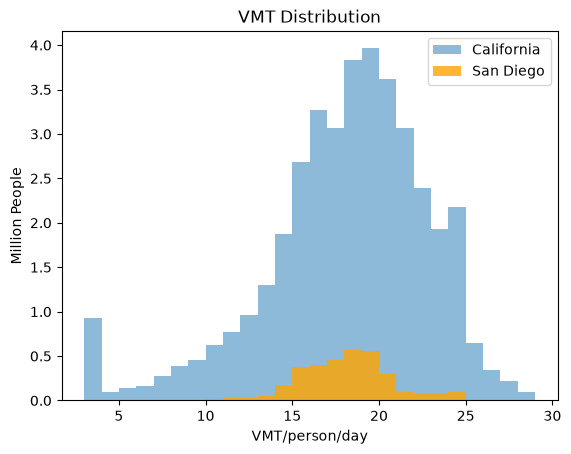

In [501]:
# Plot the statewide data
plt.hist(vmt_merged['VMTpc'], weights=vmt_merged['Population'] / 1e6, bins=np.arange(3, 30), alpha=0.5, label='California')
# Set bins to be 1 VMT from 3 to 30, use millions of people for plotting convenience.

# Filter San Diego County (state FIPS 06, county FIPS 073)
sd_vmt_merged = vmt_merged[vmt_merged.index.str.startswith('06073')]
plt.hist(sd_vmt_merged['VMTpc'], weights=sd_vmt_merged['Population'] / 1e6, bins=np.arange(3, 30), color='orange', alpha=0.8, label='San Diego')

plt.xlabel('VMT/person/day')
plt.ylabel('Million People')
plt.title('VMT Distribution')
plt.legend()



In [502]:
vmt_merged = vmt_merged.merge(gdf[['GEOID', 'ALAND']], left_index=True, right_on='GEOID', how='inner')
vmt_merged = vmt_merged.set_index('GEOID')
vmt_merged.head()

,VMTpc,Population,Housing Units,ALAND
GEOID,,,,
060259400003,24.496582,382,485,12261531
060250108002,24.612582,809,332,59331725
060250108001,24.641582,319,158,230656792
060250111003,24.642582,2010,669,1267850
060730100132,15.780582,3148,879,404606


In [503]:
vmt_merged['Population Density'] = vmt_merged['Population'] / vmt_merged['ALAND'] * 1e6 * 1.61**2
# people/m^2 * m^2/km^2 * km^2/mi^2 = people/mi^2.
vmt_merged.describe()

,VMTpc,Population,Housing Units,ALAND,Population Density
count,23190.000000,23190.000000,23190.000000,2.319000e+04,23190.000000
mean,17.870123,1693.984347,611.296938,1.740664e+07,9417.824593
std,4.770563,1116.008225,376.984896,2.047075e+08,10211.857747
min,3.991582,0.000000,0.000000,1.540600e+04,0.000000
25%,15.421832,1031.000000,380.000000,2.989952e+05,3243.531301
50%,18.429582,1475.000000,530.000000,5.462205e+05,7014.690663
75%,21.062582,2076.000000,747.000000,1.296322e+06,12071.608896
max,28.802582,38754.000000,7624.000000,1.599336e+10,188611.196936


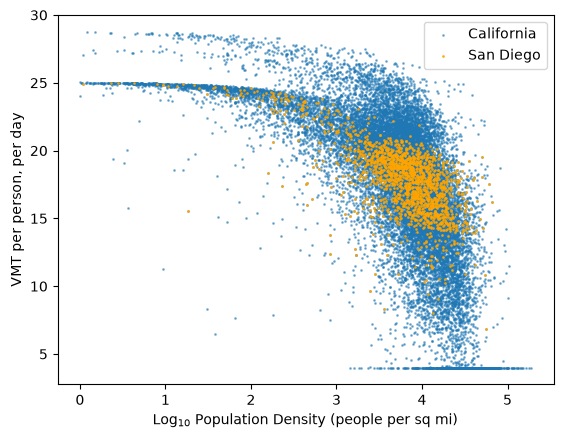

In [504]:
# Scatterplot
# First filter to rows with > 0 pop density. We'll use > 1 to avoid small floating point issues.
vmt_subset = vmt_merged[vmt_merged['Population Density'] > 1]

# Plot the statewide data
plt.scatter(np.log10(vmt_subset['Population Density']), vmt_subset['VMTpc'], s=1, alpha=0.5, label='California')

# San Diego data overlaid
sd_vmt_subset = vmt_subset[vmt_subset.index.str.startswith('06073')]
plt.scatter(np.log10(sd_vmt_subset['Population Density']), sd_vmt_subset['VMTpc'], s=1, color='orange', alpha=0.8, label='San Diego')

plt.ylabel('VMT per person, per day')
plt.xlabel('Log$_{10}$ Population Density (people per sq mi)')
plt.legend()


In [505]:
sd_vmt = sd_vmt.merge(pop, left_index=True, right_index=True, how='inner')
sd_vmt = sd_vmt.merge(housing_units,left_index=True, right_index=True, how='inner') 


In [506]:
sd_vmt.head()

,VMTpc,geometry,Population,Housing Units
GEOID,,,,
060730033051,15.308582,"POLYGON ((-117.09519 32.70412, -117.09492 32.7...",1087,225
060730083472,17.900582,"POLYGON ((-117.15141 32.92595, -117.15186 32.9...",1903,525
060730080063,17.273582,"POLYGON ((-117.26217 32.80799, -117.25928 32.8...",632,401
060730158011,15.260582,"POLYGON ((-116.96235 32.79911, -116.9581 32.79...",1834,803
060730116012,14.350582,"POLYGON ((-117.10356 32.6672, -117.09535 32.66...",1331,493


In [507]:
sd_popmean_vmt = (sd_vmt['VMTpc'] * sd_vmt['Population']).sum() / sd_vmt['Population'].sum()
sd_popmean_vmt

np.float64(18.167103324609975)

In [508]:
sd_popmean_vmt - statewide_mean_vmt_calc

np.float64(0.031531328105639744)

In [509]:
deciles = np.arange(0, 1.1, 0.1)
sd_vmt_deciles = np.quantile(sd_vmt['VMTpc'], deciles, weights=sd_vmt['Population'],
                            method='inverted_cdf')

# To make it easier to look at, let's make a dictionary using "Dictionary Comprehension" (e.g. https://www.geeksforgeeks.org/python/python-dictionary-comprehension/).
sd_vmt_deciles = {round(deciles[x], 1): round(sd_vmt_deciles[x], 1) for x in range(len(deciles))}
sd_vmt_deciles

{np.float64(0.0): np.float64(6.8),
 np.float64(0.1): np.float64(15.1),
 np.float64(0.2): np.float64(16.0),
 np.float64(0.3): np.float64(16.8),
 np.float64(0.4): np.float64(17.6),
 np.float64(0.5): np.float64(18.2),
 np.float64(0.6): np.float64(18.8),
 np.float64(0.7): np.float64(19.3),
 np.float64(0.8): np.float64(20.0),
 np.float64(0.9): np.float64(21.4),
 np.float64(1.0): np.float64(25.0)}

Below here is where Chris will try to add in San Diego (City) Data

# DP03 Economic Characteristics of San Diego County

From US Census Bureau DP03 (Economic Characteristics)
- 0004E (Total Employed)
- 0009PE Unemployment Rate
- 0062E Median Household Income
- 0119PE Percent of families below the poverty level
- 0019E Drove alone
- 0020E Carpooled
- 0021E Public Transportation (excludes rideshare)
- 0024E Worked from home
- 0025E Mean Travel time to work (in minutes)

In [510]:
# target columns / when you download a ZIP file from the US census buereau, there is a file in there called -'column-metadata.csv' and that's how you can map the column "codes" to new column names so it's easiet to filter, etc
columns_to_keep_dp03 = { # when you use {} it's called a 'dictionary' and you map key:value pairs to each other. If you download a new dataset, I recommend setting up a dictionary like this because it's very configurable and easy to add/remove new columns
    'GEO_ID': 'GEOID', 
    'DP03_0062E': 'Median_Income',
    'DP03_0128PE': 'Percent_Poverty_All_People',
    'DP03_0009PE': 'Unemployment_Rate',
    'DP03_0021E': 'Commute_Transit',
    'DP03_0024E': 'Commute_WFH',
    'DP03_0025E': 'Mean_Commute_Time_Mins'
}

# read file using the pandas .read_csv that points to where the data is stored (the inputdir is defined further up in the notebook)
df_dp03 = pd.read_csv(inputdir / 'DP03/ACSDP5Y2019.DP03-Data.csv', skiprows=[1], usecols=columns_to_keep_dp03.keys())

# rename col - this essentially says for the data frame (df) df_dp03 rename the columns using the dictionary we mapped above
df_dp03 = df_dp03.rename(columns=columns_to_keep_dp03)

# strip US from GEOID as done with VMT
df_dp03['GEOID'] = df_dp03['GEOID'].str.split('US').str[1]
df_dp03 = df_dp03.set_index('GEOID')

# if you change the number in the paranthesis it will show that number of rows in the dataframe. It defaults to 5 if you don't add a number.
df_dp03.head()

,Commute_Transit,Commute_WFH,Mean_Commute_Time_Mins,Median_Income,Unemployment_Rate,Percent_Poverty_All_People
GEOID,,,,,,
06073000100,9,203,20.1,138879,2.8,2.1
06073000201,50,67,26.3,88125,3.6,12.5
06073000202,182,266,21.7,76658,2.8,4.7
06073000300,101,288,22.0,68679,3.7,12.5
06073000400,341,214,25.3,70267,7.8,6.6


Plots for DP03

<Axes: >

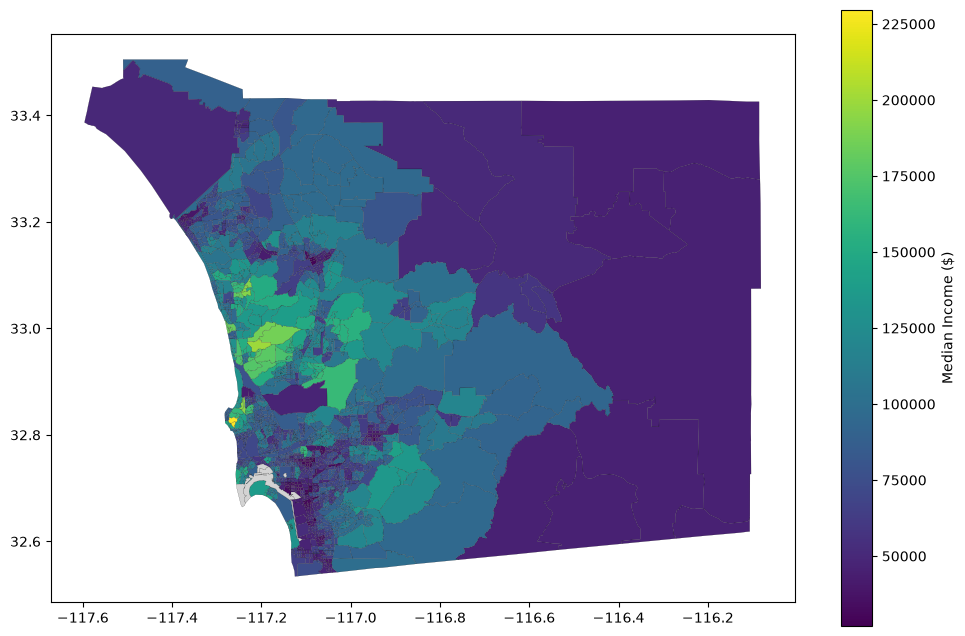

In [511]:
sd_shape['Tract_GEOID'] = sd_shape['GEOID'].str[:11] # strips first 11 characters using some neat splicing

sd_demographics = sd_shape.merge(df_dp03, left_on='Tract_GEOID', right_index=True, how='inner') # this is merging two datasets, our dp03 dataframe with the demographics dataframe that has the GEOID data so we can plot it

sd_demographics['Median_Income'] = pd.to_numeric(sd_demographics['Median_Income'], errors='coerce') # this is to 'coerce' a text value to a numeric value so that you can perform calculations on it. Essentially just formatting a string to an integer.
sd_demographics.plot(
    column='Median_Income', # you can swap this variable out with any one of the "Columns to Keep" to update the chart below, or just copy this whole code block and create a brand new chart. Don't forget to also update where it says 'Median Income' in the coerce section.
    legend=True, 
    cmap='viridis', # stylistic choice / the full library of matplotlib colors lives here: https://matplotlib.org/stable/users/explain/colors/colormaps.html
    figsize=(12, 8), # how big do you want the chart     
    edgecolor='black', # style choice for boundary
    linewidth=0.1, # thickness of the boundary line  
    missing_kwds={'color': 'lightgrey'}, # this handles any census blocks that don't have data, they will show up light grey (kwds is python for keywords)
    legend_kwds={'label': 'Median Income ($)'}
)



# DP04 Housing Characteristics of San Diego County

In [512]:
# this follows the exact same process as above but for the DP04 data set from the Census Bureau, these are some of the interesting characteristics we can use for the VMT analysis and where housing units are most prevalent
# target columns for DP04 (Housing Characteristics)
columns_to_keep_dp04 = { 
    'GEO_ID': 'GEOID', 
    'DP04_0001E': 'Total_Housing_Units',
    'DP04_0017E': 'Built_2014_or_Later',
    'DP04_0018E': 'Built_2010_to_2013',
    'DP04_0019E': 'Built_2000_to_2009',
    'DP04_0007E': 'Single_Family_Detached',
    'DP04_0008E': 'Single_Family_Attached',
    'DP04_0013E': 'Multi_Family_20_Plus',
    'DP04_0058E': 'Zero_Car_Households',
    'DP04_0059E': 'One_Car_Households',
    'DP04_0060E': 'Two_Car_Households',
    'DP04_0061E': 'Three_Plus_Car_Households',
    'DP04_0046E': 'Owner_Occupied',
    'DP04_0047E': 'Renter_Occupied'
}

df_dp04 = pd.read_csv(inputdir / 'DP04/ACSDP5Y2019.DP04-Data.csv', skiprows=[1], usecols=columns_to_keep_dp04.keys())

df_dp04 = df_dp04.rename(columns=columns_to_keep_dp04)

df_dp04['GEOID'] = df_dp04['GEOID'].str.split('US').str[1]
df_dp04 = df_dp04.set_index('GEOID')

df_dp04.head()


,Total_Housing_Units,Single_Family_Detached,Single_Family_Attached,Multi_Family_20_Plus,Built_2014_or_Later,Built_2010_to_2013,Built_2000_to_2009,Owner_Occupied,Renter_Occupied,Zero_Car_Households,One_Car_Households,Two_Car_Households,Three_Plus_Car_Households
GEOID,,,,,,,,,,,,,
06073000100,1383,1275,0,45,10,0,29,1110,148,59,269,580,350
06073000201,1147,522,58,299,10,36,118,549,531,127,517,323,113
06073000202,2472,1138,224,393,18,36,55,986,1347,208,1069,701,355
06073000300,3209,337,248,1169,18,13,279,774,2230,193,1774,852,185
06073000400,2433,262,127,1409,0,21,316,354,1684,184,1064,576,214


<Axes: >

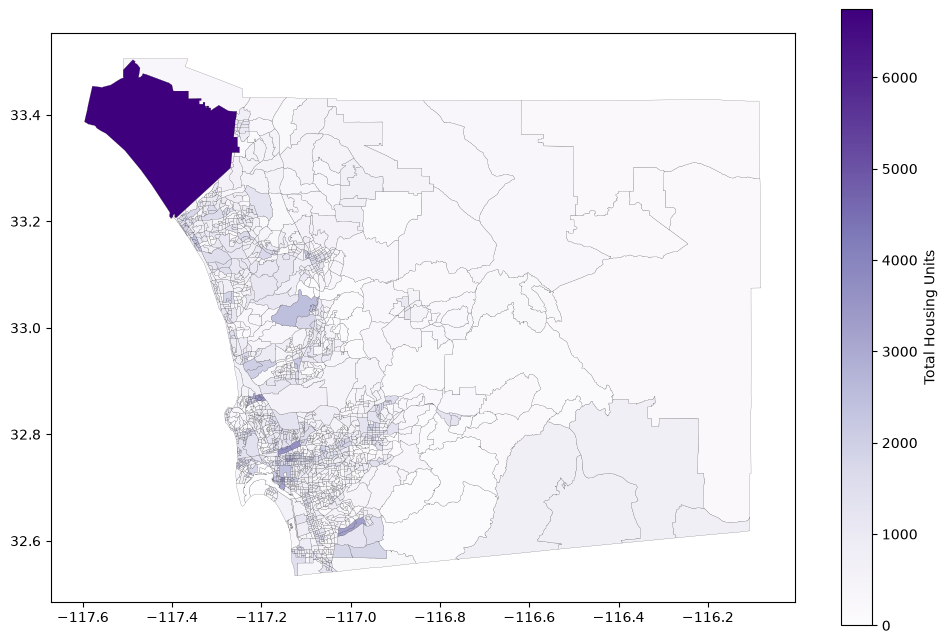

In [513]:
sd_housing = sd_shape.merge(df_dp04, left_on='Tract_GEOID', right_index=True, how='inner')

sd_housing['Renter_Occupied'] = pd.to_numeric(sd_housing['Renter_Occupied'], errors='coerce')

sd_housing.plot(
    column='Renter_Occupied', 
    legend=True, 
    cmap='Purples', 
    figsize=(12, 8),      
    edgecolor='black', 
    linewidth=0.1,   
    missing_kwds={'color': 'lightgrey'}, 
    legend_kwds={'label': 'Total Housing Units'}
)

# DP05 Demographics and Housing Charcteristics of San Diego County

In [514]:
columns_to_keep_dp05 = { 
    'GEO_ID': 'GEOID', 
    'DP05_0001E': 'Total_Population',
    'DP05_0071E': 'Pop_Hispanic_Latino',
    'DP05_0077E': 'Pop_White_Non_Hispanic',
    'DP05_0078E': 'Pop_Black_Non_Hispanic',
    'DP05_0080E': 'Pop_Asian_Non_Hispanic',
    'DP05_0079E': 'Pop_Native_American_Non_Hispanic',
    'DP05_0081E': 'Pop_Pacific_Islander_Non_Hispanic',
    'DP05_0083E': 'Pop_Two_Or_More_Races'
}


df_dp05 = pd.read_csv(inputdir / 'DP05/ACSDP5Y2019.DP05-Data.csv', skiprows=[1], usecols=columns_to_keep_dp05.keys())

df_dp05 = df_dp05.rename(columns=columns_to_keep_dp05)

df_dp05['GEOID'] = df_dp05['GEOID'].str.split('US').str[1]
df_dp05 = df_dp05.set_index('GEOID')

df_dp05.head()


,Total_Population,Pop_Hispanic_Latino,Pop_White_Non_Hispanic,Pop_Black_Non_Hispanic,Pop_Native_American_Non_Hispanic,Pop_Asian_Non_Hispanic,Pop_Pacific_Islander_Non_Hispanic,Pop_Two_Or_More_Races
GEOID,,,,,,,,
06073000100,3093,489,2389,0,0,112,0,103
06073000201,1891,140,1569,10,11,75,0,86
06073000202,4542,616,3390,4,0,379,3,150
06073000300,5239,871,3820,266,0,146,7,129
06073000400,3801,884,2148,228,0,430,0,93


<Axes: >

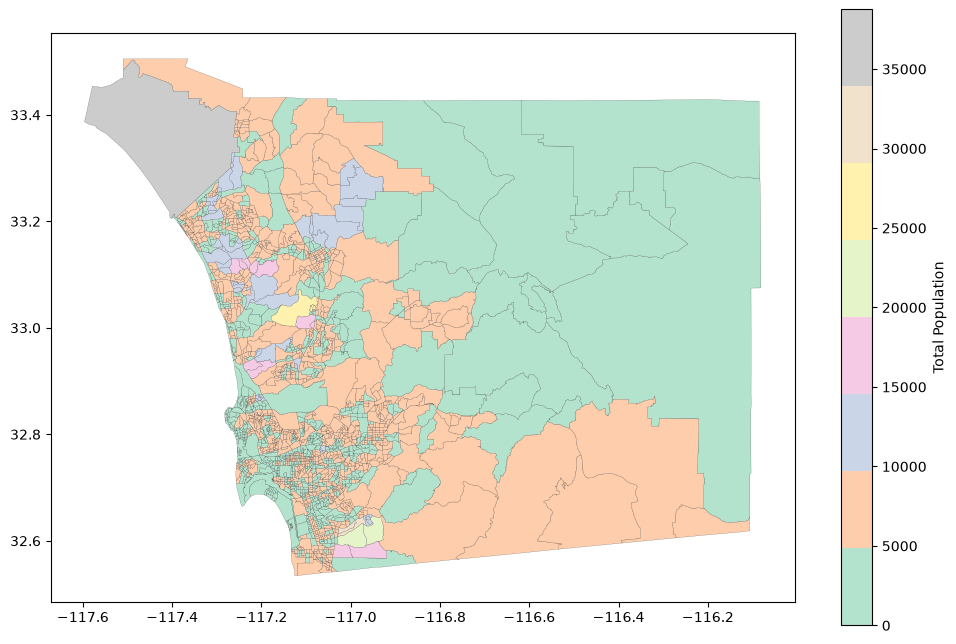

In [515]:
sd_demographics = sd_shape.merge(df_dp05, left_on='Tract_GEOID', right_index=True, how='inner')

sd_demographics['Total_Population'] = pd.to_numeric(sd_demographics['Total_Population'], errors='coerce')

sd_demographics.plot(
    column='Total_Population', 
    legend=True, 
    cmap='Pastel2', 
    figsize=(12, 8),      
    edgecolor='black', 
    linewidth=0.1,   
    missing_kwds={'color': 'lightgrey'}, 
    legend_kwds={'label': 'Total Population'}
)

# S0801 Commuting Characteristics by Sex in San Diego County

In [516]:
columns_to_keep_S0801 = {
    'GEO_ID': 'GEOID',
    
    # primary commuting population
    'S0801_C01_001E': 'Total_Workers_16_Plus',
    'S0801_C01_002E': 'Commute_Car_Truck_Van',
    'S0801_C01_003E': 'Commute_Drove_Alone',
    'S0801_C01_004E': 'Commute_Carpooled',
    'S0801_C01_009E': 'Commute_Public_Transit',
    'S0801_C01_010E': 'Commute_Walked',
    'S0801_C01_011E': 'Commute_Bicycle',
    'S0801_C01_013E': 'Commute_Worked_From_Home',
    'S0801_C01_046E': 'Mean_Travel_Time_Minutes',
    'S0801_C01_047E': 'Total_Workers_In_Households',
    'S0801_C01_048E': 'No_Vehicle_Available',
    'S0801_C01_049E': 'One_Vehicle_Available'
}

df_S0801 = pd.read_csv(inputdir / 'S0801/ACSST5Y2019.S0801-Data.csv', skiprows=[1], usecols=columns_to_keep_S0801.keys())

df_S0801 = df_S0801.rename(columns=columns_to_keep_S0801)

df_S0801['GEOID'] = df_S0801['GEOID'].str.split('US').str[1]
df_S0801 = df_S0801.set_index('GEOID')

df_S0801.head()


,Total_Workers_16_Plus,Commute_Car_Truck_Van,Commute_Drove_Alone,Commute_Carpooled,Commute_Public_Transit,Commute_Walked,Commute_Bicycle,Commute_Worked_From_Home,Mean_Travel_Time_Minutes,Total_Workers_In_Households,No_Vehicle_Available,One_Vehicle_Available
GEOID,,,,,,,,,,,,
06073000100,1440,80.8,76.7,4.1,0.6,4.0,0.0,14.1,20.1,1440,0.0,6.7
06073000201,957,81.9,76.8,5.1,5.2,2.8,0.8,7.0,26.3,957,0.0,34.2
06073000202,2790,76.5,72.8,3.6,6.5,1.3,3.8,9.5,21.7,2790,3.6,31.5
06073000300,3381,76.2,73.2,3.0,3.0,7.4,2.7,8.5,22.0,3371,0.6,47.7
06073000400,2500,72.2,69.6,2.6,13.6,4.6,1.0,8.6,25.3,2500,9.1,37.4


<Axes: >

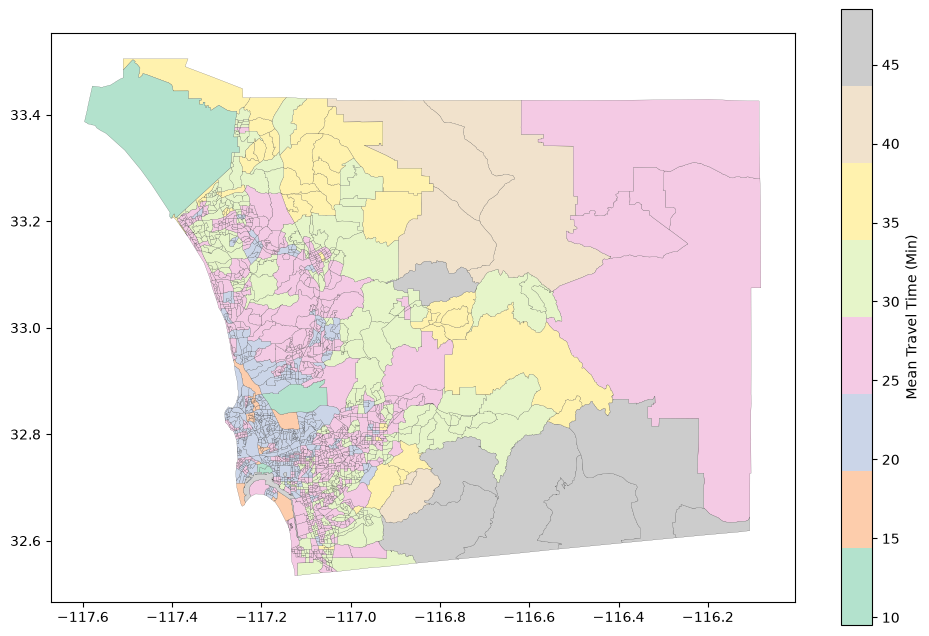

In [517]:
sd_commuting = sd_shape.merge(df_S0801, left_on='Tract_GEOID', right_index=True, how='inner')

sd_commuting['Mean_Travel_Time_Minutes'] = pd.to_numeric(sd_commuting['Mean_Travel_Time_Minutes'], errors='coerce')

sd_commuting.plot(
    column='Mean_Travel_Time_Minutes', 
    legend=True, 
    cmap='Pastel2', 
    figsize=(12, 8),      
    edgecolor='black', 
    linewidth=0.1,   
    missing_kwds={'color': 'lightgrey'}, 
    legend_kwds={'label': 'Mean Travel Time (Min)'}
)

# Master Join of all Census Bureau Datasets

In [518]:
# merge all of the census data into a single dataframe

df_census = df_dp03.join([df_dp04, df_dp05, df_S0801], how='outer').reset_index()

df_census.head()

,GEOID,Commute_Transit,Commute_WFH,Mean_Commute_Time_Mins,Median_Income,Unemployment_Rate,Percent_Poverty_All_People,Total_Housing_Units,Single_Family_Detached,Single_Family_Attached,...,Commute_Drove_Alone,Commute_Carpooled,Commute_Public_Transit,Commute_Walked,Commute_Bicycle,Commute_Worked_From_Home,Mean_Travel_Time_Minutes,Total_Workers_In_Households,No_Vehicle_Available,One_Vehicle_Available
0,06073000100,9,203,20.1,138879,2.8,2.1,1383,1275,0,...,76.7,4.1,0.6,4.0,0.0,14.1,20.1,1440,0.0,6.7
1,06073000201,50,67,26.3,88125,3.6,12.5,1147,522,58,...,76.8,5.1,5.2,2.8,0.8,7.0,26.3,957,0.0,34.2
2,06073000202,182,266,21.7,76658,2.8,4.7,2472,1138,224,...,72.8,3.6,6.5,1.3,3.8,9.5,21.7,2790,3.6,31.5
3,06073000300,101,288,22.0,68679,3.7,12.5,3209,337,248,...,73.2,3.0,3.0,7.4,2.7,8.5,22.0,3371,0.6,47.7
4,06073000400,341,214,25.3,70267,7.8,6.6,2433,262,127,...,69.6,2.6,13.6,4.6,1.0,8.6,25.3,2500,9.1,37.4


In [519]:
# first step to strip the first 11 characters from the Tract Geoid from the VMT dataset
data_cleaned = data_cleaned.reset_index()

data_cleaned['Tract_GEOID'] = data_cleaned['GEOID'].str[:11]

df_master = pd.merge(data_cleaned, df_census,
left_on='Tract_GEOID',
right_on='GEOID',
how='inner')

df_master.head()

,GEOID_x,VMT_diff_state,Tract_GEOID,GEOID_y,Commute_Transit,Commute_WFH,Mean_Commute_Time_Mins,Median_Income,Unemployment_Rate,Percent_Poverty_All_People,...,Commute_Drove_Alone,Commute_Carpooled,Commute_Public_Transit,Commute_Walked,Commute_Bicycle,Commute_Worked_From_Home,Mean_Travel_Time_Minutes,Total_Workers_In_Households,No_Vehicle_Available,One_Vehicle_Available
0,060730100132,-2.346,06073010013,06073010013,245,108,31.5,43856,13.0,21.9,...,64.6,13.0,11.1,4.7,0.0,4.9,31.5,2209,5.0,26.7
1,060730101033,-0.942,06073010103,06073010103,197,96,31.9,46354,8.6,18.5,...,71.4,15.5,6.7,2.0,0.0,3.3,31.9,2942,4.0,22.8
2,060730101042,-0.103,06073010104,06073010104,137,27,32.0,61801,6.1,10.4,...,77.5,13.1,7.9,0.0,0.0,1.6,32.0,1734,2.2,17.3
3,060730101032,-1.392,06073010103,06073010103,197,96,31.9,46354,8.6,18.5,...,71.4,15.5,6.7,2.0,0.0,3.3,31.9,2942,4.0,22.8
4,060730101061,-3.233,06073010106,06073010106,237,22,26.0,45417,14.3,16.6,...,75.2,10.3,10.1,1.7,0.0,0.9,26.0,2346,4.6,14.5


In [520]:
# drop redundant columns and rename GEOID_x to GEOID for easier legibility

df_master = df_master.drop(columns=['GEOID_y', 'Tract_GEOID'])
df_master = df_master.rename(columns={'GEOID_x': 'GEOID'})

df_master.head()

,GEOID,VMT_diff_state,Commute_Transit,Commute_WFH,Mean_Commute_Time_Mins,Median_Income,Unemployment_Rate,Percent_Poverty_All_People,Total_Housing_Units,Single_Family_Detached,...,Commute_Drove_Alone,Commute_Carpooled,Commute_Public_Transit,Commute_Walked,Commute_Bicycle,Commute_Worked_From_Home,Mean_Travel_Time_Minutes,Total_Workers_In_Households,No_Vehicle_Available,One_Vehicle_Available
0,060730100132,-2.346,245,108,31.5,43856,13.0,21.9,1628,448,...,64.6,13.0,11.1,4.7,0.0,4.9,31.5,2209,5.0,26.7
1,060730101033,-0.942,197,96,31.9,46354,8.6,18.5,1948,738,...,71.4,15.5,6.7,2.0,0.0,3.3,31.9,2942,4.0,22.8
2,060730101042,-0.103,137,27,32.0,61801,6.1,10.4,1110,956,...,77.5,13.1,7.9,0.0,0.0,1.6,32.0,1734,2.2,17.3
3,060730101032,-1.392,197,96,31.9,46354,8.6,18.5,1948,738,...,71.4,15.5,6.7,2.0,0.0,3.3,31.9,2942,4.0,22.8
4,060730101061,-3.233,237,22,26.0,45417,14.3,16.6,1638,291,...,75.2,10.3,10.1,1.7,0.0,0.9,26.0,2346,4.6,14.5


# Correlation Heatmaps with VMT and Census Dataframes

In [521]:
# primary correlation variable
corr_var = 'VMT_diff_state'

DP03 Correlation Matrix

In [522]:
for col in df_dp03.columns:
    df_dp03[col] = pd.to_numeric(df_dp03[col], errors='coerce') # loop through and coerce all values

vmt_tract_level_dp03 = df_master[['GEOID', corr_var]].copy()
vmt_tract_level_dp03['GEOID'] = vmt_tract_level_dp03['GEOID'].astype(str).str[:-1]
vmt_tract_level_dp03 = vmt_tract_level_dp03.set_index('GEOID')

df_dp03.index = df_dp03.index.astype(str) # reset the GEOID to string

df_analysis_dp03 = df_dp03.join(vmt_tract_level_dp03, how='inner')

vmt_correlations_dp03 = df_analysis_dp03.corr()[[corr_var]].sort_values(by=corr_var, ascending=False)
vmt_correlations_dp03


,VMT_diff_state
VMT_diff_state,1.000000
Median_Income,0.432452
Mean_Commute_Time_Mins,0.403994
Commute_WFH,0.220617
Unemployment_Rate,-0.196405
Percent_Poverty_All_People,-0.406091
Commute_Transit,-0.488144


Plot the Matrix

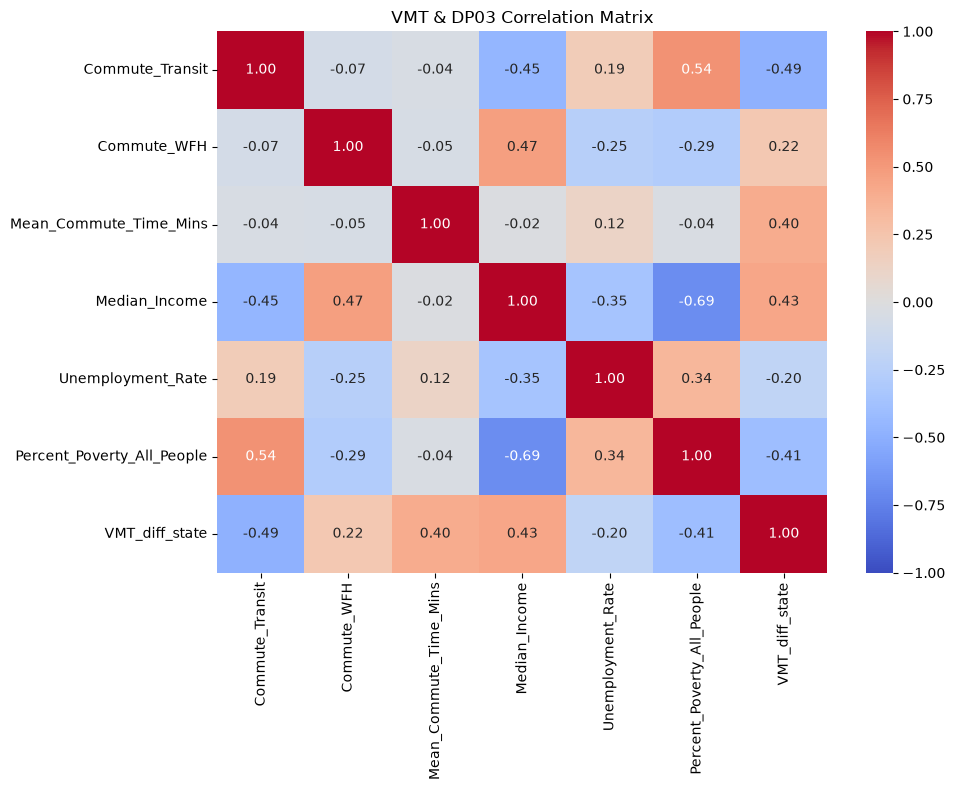

In [523]:
plt.figure(figsize=(10, 8))

full_matrix_dp03 = df_analysis_dp03.corr()

sns.heatmap(full_matrix_dp03, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('VMT & DP03 Correlation Matrix')

plt.tight_layout()
plt.show()


DP04 Correlation Matrix

In [524]:
for col in df_dp04.columns:
    df_dp04[col] = pd.to_numeric(df_dp04[col], errors='coerce') 

vmt_tract_level_dp04 = df_master[['GEOID', corr_var]].copy()
vmt_tract_level_dp04['GEOID'] = vmt_tract_level_dp04['GEOID'].astype(str).str[:-1]
vmt_tract_level_dp04 = vmt_tract_level_dp04.set_index('GEOID')

df_dp04.index = df_dp04.index.astype(str) # reset the GEOID to string

df_analysis_dp04 = df_dp04.join(vmt_tract_level_dp04, how='inner')

vmt_correlations_dp04 = df_analysis_dp04.corr()[[corr_var]].sort_values(by=corr_var, ascending=False)
vmt_correlations_dp04

,VMT_diff_state
VMT_diff_state,1.000000
Three_Plus_Car_Households,0.514775
Single_Family_Detached,0.509712
Owner_Occupied,0.469067
Two_Car_Households,0.180002
Built_2000_to_2009,0.125021
Built_2010_to_2013,0.087022
Total_Housing_Units,0.059159
Single_Family_Attached,0.032753
Built_2014_or_Later,0.006204


Plot the Matrix

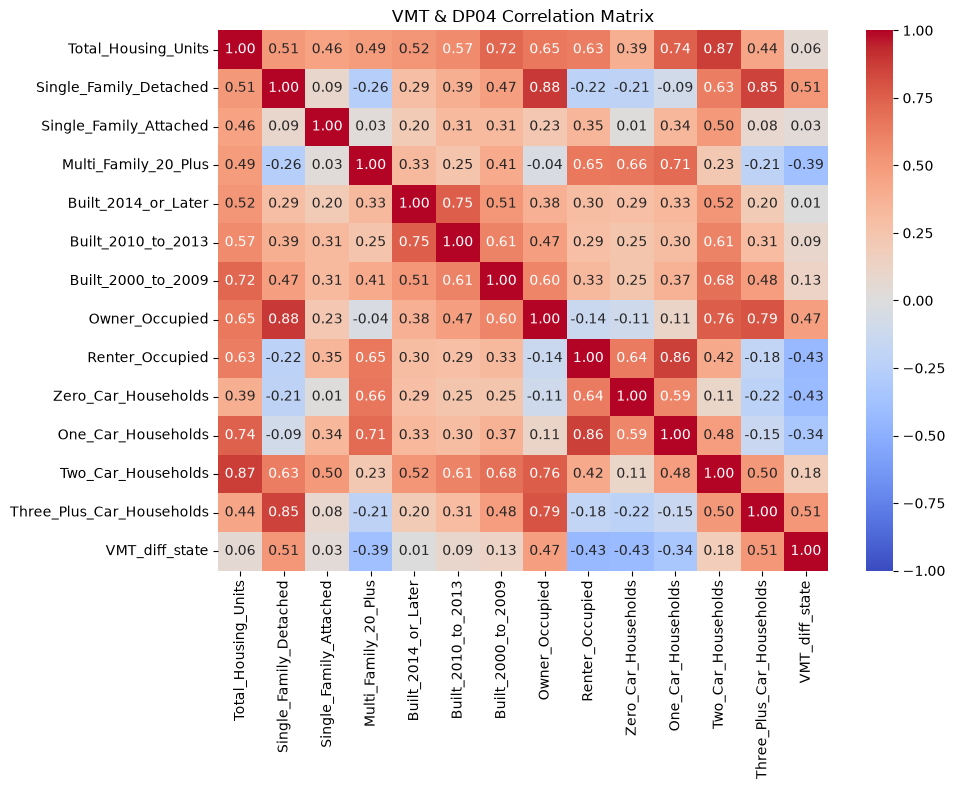

In [525]:
plt.figure(figsize=(10, 8))

full_matrix_dp04 = df_analysis_dp04.corr()

sns.heatmap(full_matrix_dp04, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('VMT & DP04 Correlation Matrix')

plt.tight_layout()
plt.show()

DP05 Correlation Matrix

In [526]:
for col in df_dp05.columns:
    df_dp05[col] = pd.to_numeric(df_dp05[col], errors='coerce') 

vmt_tract_level_dp05 = df_master[['GEOID', corr_var]].copy()
vmt_tract_level_dp05['GEOID'] = vmt_tract_level_dp05['GEOID'].astype(str).str[:-1]
vmt_tract_level_dp05 = vmt_tract_level_dp05.set_index('GEOID')

df_dp05.index = df_dp05.index.astype(str) # reset the GEOID to string

df_analysis_dp05 = df_dp05.join(vmt_tract_level_dp05, how='inner')

vmt_correlations_dp05 = df_analysis_dp05.corr()[[corr_var]].sort_values(by=corr_var, ascending=False)
vmt_correlations_dp05

,VMT_diff_state
VMT_diff_state,1.000000
Pop_White_Non_Hispanic,0.388087
Pop_Native_American_Non_Hispanic,0.242558
Total_Population,0.157500
Pop_Two_Or_More_Races,0.157089
Pop_Asian_Non_Hispanic,-0.019636
Pop_Pacific_Islander_Non_Hispanic,-0.030700
Pop_Hispanic_Latino,-0.149600
Pop_Black_Non_Hispanic,-0.266375


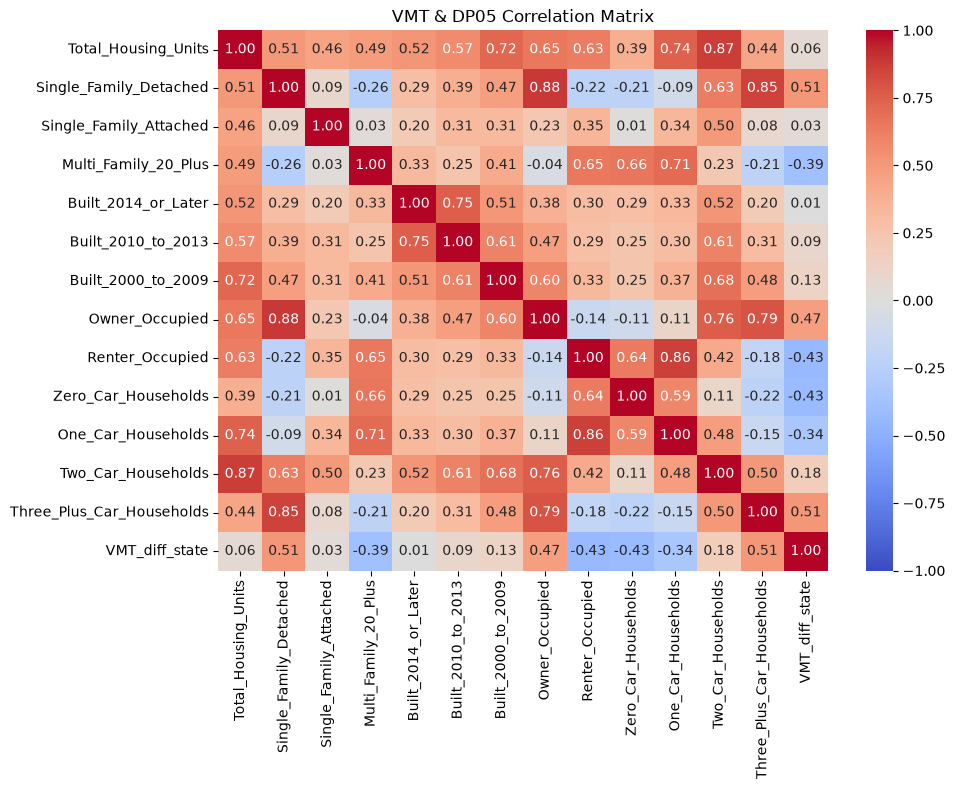

In [527]:
plt.figure(figsize=(10, 8))

full_matrix_dp05 = df_analysis_dp04.corr()

sns.heatmap(full_matrix_dp05, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('VMT & DP05 Correlation Matrix')

plt.tight_layout()
plt.show()

S0801 Correlation Matrix

In [528]:
for col in df_S0801.columns:
    df_S0801[col] = pd.to_numeric(df_S0801[col], errors='coerce') 

vmt_tract_level_S0801 = df_master[['GEOID', corr_var]].copy()
vmt_tract_level_S0801['GEOID'] = vmt_tract_level_S0801['GEOID'].astype(str).str[:-1]
vmt_tract_level_S0801 = vmt_tract_level_S0801.set_index('GEOID')

df_S0801.index = df_S0801.index.astype(str) # reset the GEOID to string

df_analysis_S0801 = df_S0801.join(vmt_tract_level_S0801, how='inner')

vmt_correlations_S0801 = df_analysis_S0801.corr()[[corr_var]].sort_values(by=corr_var, ascending=False)
vmt_correlations_S0801

,VMT_diff_state
VMT_diff_state,1.000000
Mean_Travel_Time_Minutes,0.403994
Commute_Drove_Alone,0.306345
Commute_Worked_From_Home,0.268879
Commute_Car_Truck_Van,0.223375
Total_Workers_16_Plus,0.070724
Total_Workers_In_Households,0.062368
Commute_Carpooled,-0.162088
Commute_Walked,-0.225116
Commute_Bicycle,-0.261810


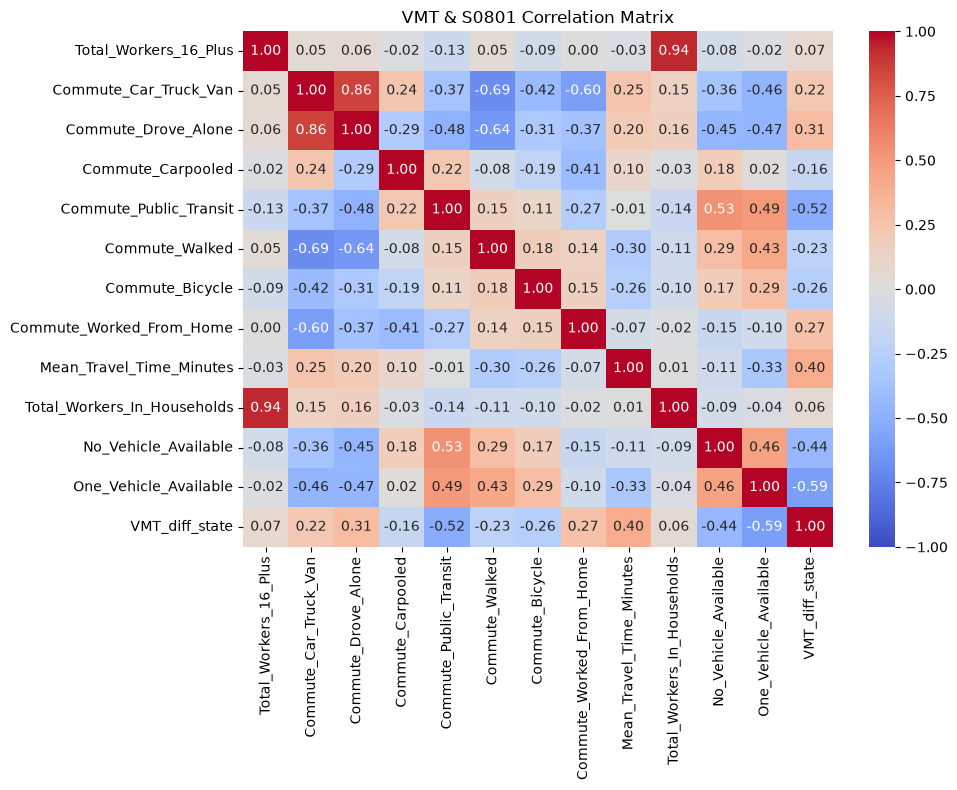

In [529]:
plt.figure(figsize=(10, 8))

full_matrix_S0801 = df_analysis_S0801.corr()

sns.heatmap(full_matrix_S0801, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('VMT & S0801 Correlation Matrix')

plt.tight_layout()
plt.show()

Master Correlation

In [530]:
master_correlations = pd.concat([ # concatenace all of the correlation results
    vmt_correlations_dp03, 
    vmt_correlations_dp04,
    vmt_correlations_dp05,
    vmt_correlations_S0801
])

master_correlations = master_correlations.drop('VMT_diff_state', errors='ignore')

master_rank = master_correlations.sort_values(by='VMT_diff_state', ascending=False)

master_rank

,VMT_diff_state
Three_Plus_Car_Households,0.514775
Single_Family_Detached,0.509712
Owner_Occupied,0.469067
Median_Income,0.432452
Mean_Travel_Time_Minutes,0.403994
Mean_Commute_Time_Mins,0.403994
Pop_White_Non_Hispanic,0.388087
Commute_Drove_Alone,0.306345
Commute_Worked_From_Home,0.268879
Pop_Native_American_Non_Hispanic,0.242558


# San Diego Percentiles

In [531]:
percentiles = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] # make a list of percentile values to loop through

sd_percentiles = df_master['VMT_diff_state'].quantile(percentiles)

print(sd_percentiles)

0.1   -3.2358
0.2   -2.3488
0.3   -1.6084
0.4   -0.7786
0.5   -0.1325
0.6    0.4652
0.7    0.9711
0.8    1.4928
0.9    2.5024
Name: VMT_diff_state, dtype: float64


In [532]:
for p, value in sd_percentiles.items():
    print(f"{int(p*100)}th Percentile Block Group: {value:.3f}") # round to three decimal places


10th Percentile Block Group: -3.236
20th Percentile Block Group: -2.349
30th Percentile Block Group: -1.608
40th Percentile Block Group: -0.779
50th Percentile Block Group: -0.133
60th Percentile Block Group: 0.465
70th Percentile Block Group: 0.971
80th Percentile Block Group: 1.493
90th Percentile Block Group: 2.502


# OVERVIEW AND RESULS FOR SAN DIEGO COUNTY

In [533]:
total_population = sd_vmt_merged['Population'].sum()
average_vmt = (sd_vmt_merged['VMTpc'] * sd_vmt_merged['Population']).sum() / total_population

print(f"Total Population (Block Groups): {total_population:,.0f}")
print(f"Average VMT per person-day: {average_vmt:.2f} miles per day")

Total Population (Block Groups): 3,316,073
Average VMT per person-day: 18.17 miles per day


In [534]:
sd_10th = sd_vmt_merged['VMTpc'].quantile(0.10)
efficient_block_group = sd_vmt_merged[sd_vmt_merged['VMTpc'] <= sd_10th]

avg_vmt_efficient = (efficient_block_group['VMTpc'] * efficient_block_group['Population']).sum() / efficient_block_group['Population'].sum()
print(f"To be in the Top 10%, a block group must have a VMT under: {sd_10th:.2f} miles/day")
print(f"Average VMT within these efficient block groups: {avg_vmt_efficient:.2f} miles/day")

To be in the Top 10%, a block group must have a VMT under: 14.89 miles/day
Average VMT within these efficient block groups: 13.40 miles/day


Assume San Diego Country approves a 12,000 unit housing development. What are the avoided emissions of building in the top 10th percentile neighborhood compared to the county average?

In [ ]:
# FUN FACT: San Diego added more people to its population between 2022-2025 than any other county in the state, except for Riverside. 36,000 housing units were added during that period, for an annual average of 12,000 units.

new_housing_units = 12000 # https://chpd.ucsd.edu/san-diegos-population-is-growing-is-housing-construction-keeping-up-kind-of/ // good review of San Diego housing policy - Terner Housing connection!
people_per_unit = 2.8 # https://www.point2homes.com/US/Neighborhood/CA/San-Diego-County-Demographics.html // source for total housing units, occupants per household, etc
new_drivers = new_housing_units * people_per_unit

gas_ghgs_per_gallon = 8.78 # emissions factor from HW# 1 - kg CO2e per gallon
mpg = 25

gas_ghgs_tonnes = (gas_ghgs_per_gallon / 1000) / mpg # convert to metric tonnes

vmt_saved_per_person_day = average_vmt - avg_vmt_efficient # difference between country AVERAGE VMT, and the VMT of an efficient neighborhood

vmt_saved_per_year = new_drivers * vmt_saved_per_person_day * 365 # annual savings

ghg_offset_mt_yr = vmt_saved_per_year * gas_ghgs_tonnes

print(f"Building {new_housing_units:,} units in the Top 10% most efficient block groups")
print(f"VMT saved per person, per day: {vmt_saved_per_person_day:.2f} miles")
print(f"Total VMT reduced per year: {vmt_saved_per_year:,.0f} miles")
print(f"Total Annual Tailpipe Emissions Reduced: {ghg_offset_mt_yr:,.0f} Metric Tonnes of CO2e")


Building 12,000 units in the Top 10% most efficient block groups
VMT saved per person, per day: 4.76 miles
Total VMT reduced per year: 58,409,913 miles
Total Annual Tailpipe Emissions Offset: 20,514 Metric Tonnes of CO2e


# Plot Results

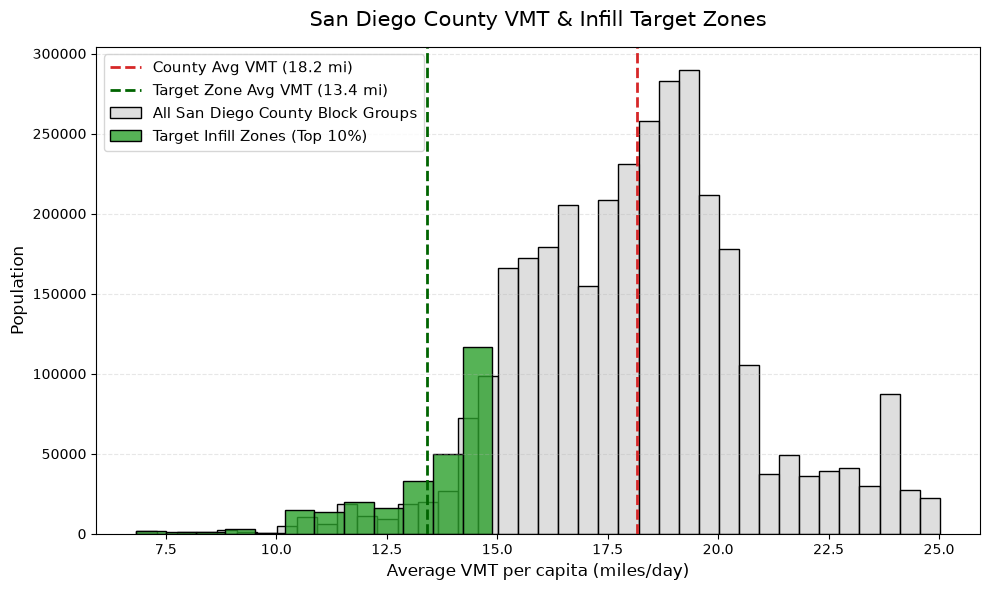

In [ ]:
# Using seaborn histplot to show the county average VMT, and the 10th percentile VMT, and the target infill zones to acheive the carbon reductions
# documentation: https://seaborn.pydata.org/generated/seaborn.histplot.html


plt.figure(figsize=(10, 6))

# histogram of the VMT per capita for San Diego's population
sns.histplot(data=sd_vmt_merged, x='VMTpc', weights='Population', 
             bins=40, color='lightgray', label='All San Diego County Block Groups')

# color the efficient block group - overlay isn't perfect, but the coverage works as an indicator
sns.histplot(data=efficient_block_group, x='VMTpc', weights='Population', 
             bins=12, color='#2ca02c', label='Target Infill Zones (Top 10%)', alpha=0.8)

# add an axis reference line for the county VMT average
plt.axvline(average_vmt, color='#d62728', linestyle='dashed', linewidth=2, 
            label=f'County Avg VMT ({average_vmt:.1f} mi)')

# add an axis for the target VMT
plt.axvline(avg_vmt_efficient, color='#006400', linestyle='dashed', linewidth=2, 
            label=f'Target Zone Avg VMT ({avg_vmt_efficient:.1f} mi)')

plt.title('San Diego County VMT & Infill Target Zones', fontsize=15, pad=15)
plt.xlabel('Average VMT per capita (miles/day)', fontsize=12)
plt.ylabel('Population', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

plt.show()


# WHERE ARE THOSE 10TH PERCENTILE BLOCK GROUPS LOCATED?

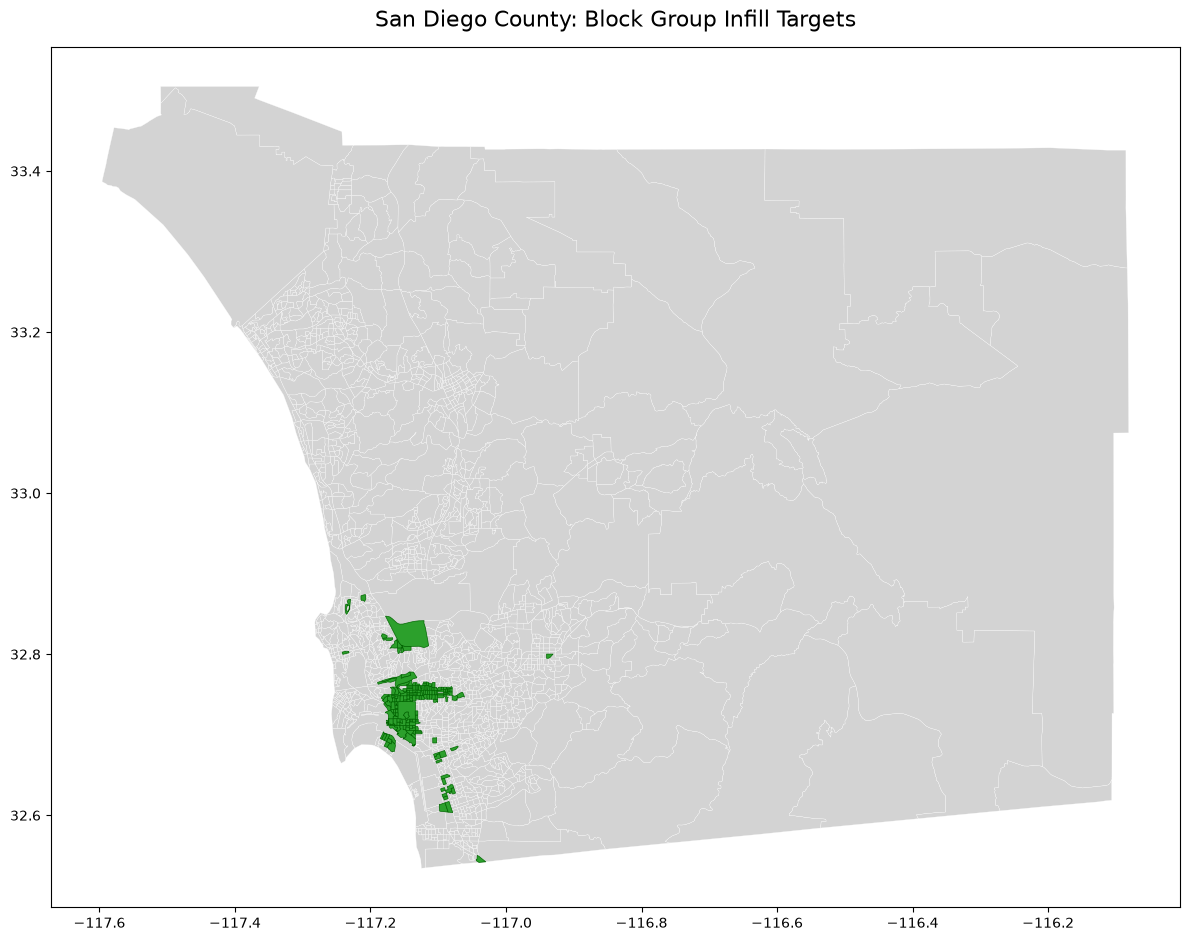

In [ ]:
sd_infill_map = sd_shape.copy() # copy the San Diego county shape

sd_infill_map['SD_10_Zone'] = sd_map_data['GEOID'].isin(efficient_block_group.index)

fig, ax = plt.subplots(1, 1, figsize=(12, 12))

# start with grey map
sd_map_data.plot(
    ax=ax, 
    color='lightgrey', 
    edgecolor='white', 
    linewidth=0.2
)

# overlay the 10th percentile block groups
sd_map_data[sd_map_data['SD_10_Zone']].plot(
    ax=ax, 
    color='#2ca02c', 
    edgecolor='darkgreen', 
    linewidth=0.5
)

plt.title('Block Group Infill Targets', fontsize=16, pad=15)
plt.tight_layout()
plt.show()

# COMPARE THE TARGET CENSUS BLOCKS TO HISTORICAL TRENDS IN HOUSING DEVELOPMENT

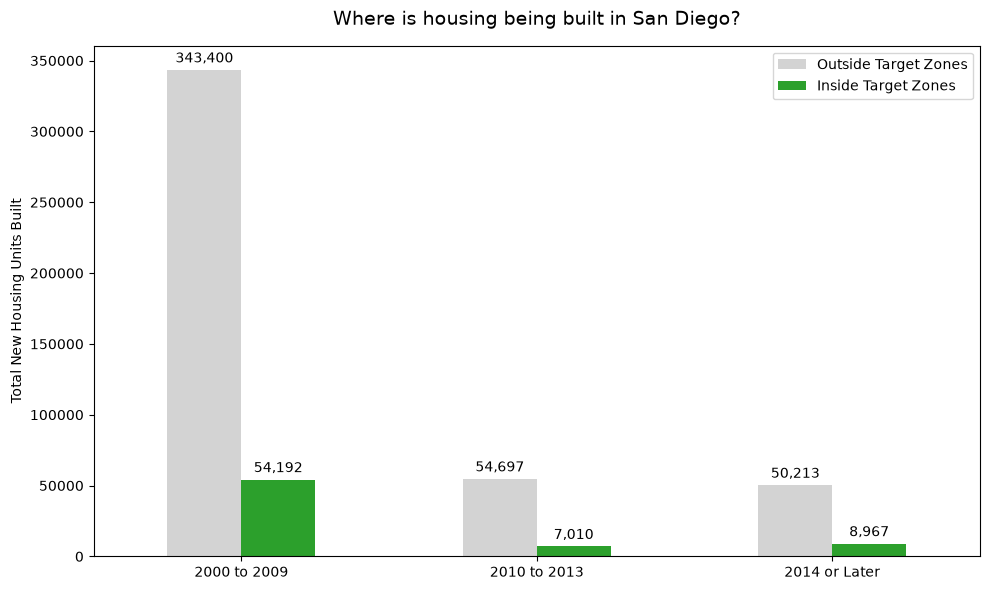

In [567]:
sd_housing['Target_Zone'] = sd_housing['GEOID'].isin(efficient_block_group.index)

# pulled from census DP04 dataset
historical_trends = sd_housing.groupby('Target_Zone')[['Built_2000_to_2009', 'Built_2010_to_2013', 'Built_2014_or_Later']].sum()

plot_data = historical_trends.T 

plot_data.columns = ['Outside Target Zones', 'Inside Target Zones']
plot_data.index = ['2000 to 2009', '2010 to 2013', '2014 or Later'] 


ax = plot_data.plot(kind='bar', figsize=(10, 6), color=['lightgrey', '#2ca02c'], rot=0)

ax.set_ylabel('Total New Housing Units Built')
ax.set_title('Where is housing being built in San Diego?', fontsize=14, pad=15)

for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='{:,.0f}')

plt.tight_layout()
plt.show()


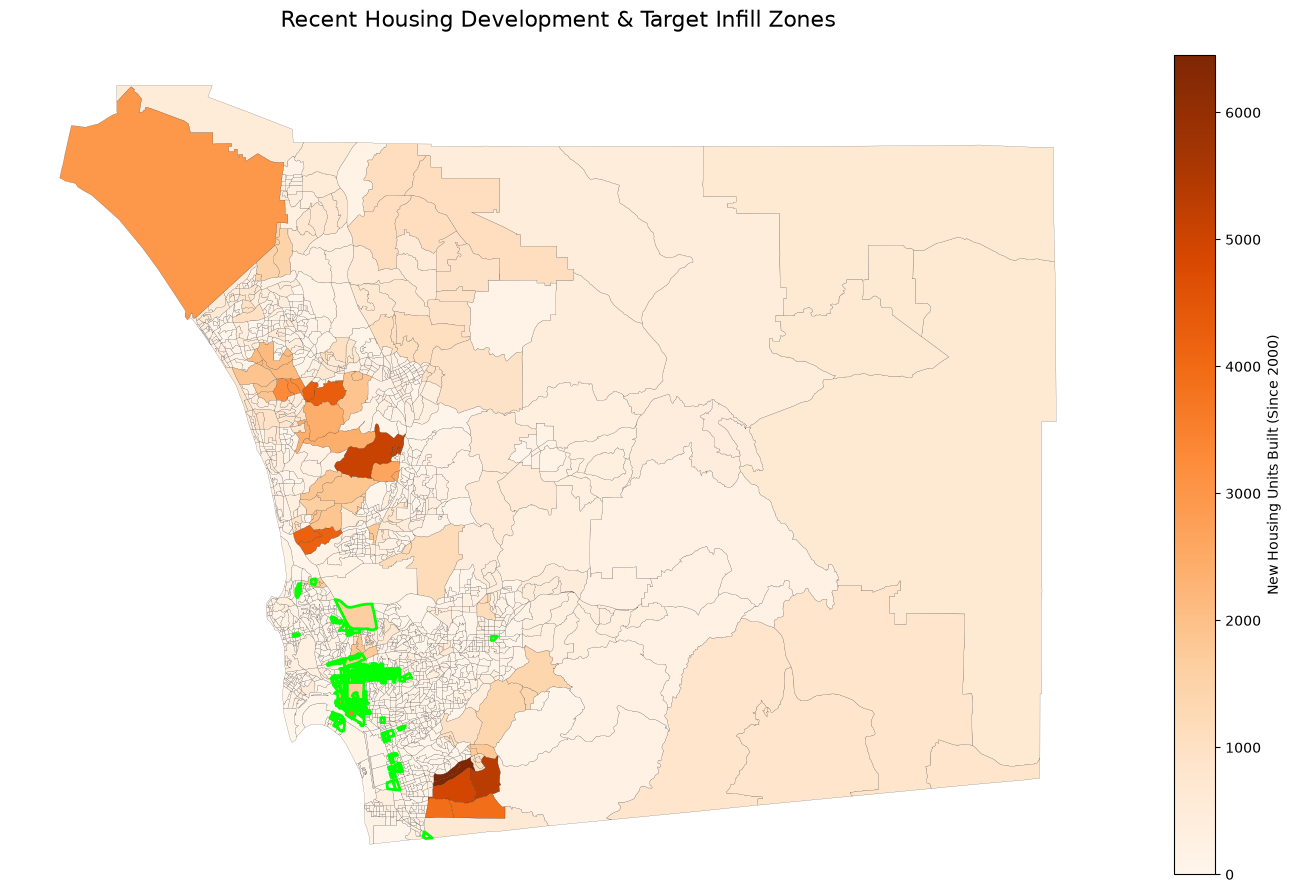

In [568]:
# create a new column that sums up all of the available housing from DP04
sd_housing['New_Housing_Since_2000'] = (
    pd.to_numeric(sd_housing['Built_2014_or_Later']) + 
    pd.to_numeric(sd_housing['Built_2010_to_2013']) + 
    pd.to_numeric(sd_housing['Built_2000_to_2009'])
)


sd_housing['Target_Zone'] = sd_housing['GEOID'].isin(efficient_block_group.index)

fig, ax = plt.subplots(1, 1, figsize=(14, 12))

sd_housing.plot(
    column='New_Housing_Since_2000', 
    ax=ax,
    cmap='Oranges', 
    legend=True,
    legend_kwds={'label': 'New Housing Units Built (Since 2000)', 'shrink': 0.7},
    edgecolor='black',
    linewidth=0.1
)

sd_housing[sd_housing['Target_Zone']].plot(
    ax=ax,
    facecolor='none',       
    edgecolor='#00FF00',  
    linewidth=2,
    label='Target Infill Zones'
)


plt.title('Recent Housing Development & Target Infill Zones', fontsize=16, pad=15)
ax.axis('off')
plt.tight_layout()

plt.show()
